# 1 · Transformers & Pipelines in scikit-learn

Everything in scikit-learn shares one API:

| Object | Methods | Example |
|---|---|---|
| **Transformer** | `fit(X)` learns parameters, then `transform(X)` applies them | `StandardScaler` learns mean and std |
| **Estimator / model** | `fit(X, y)`, `predict(X)` | `LogisticRegression` |
| **Pipeline** | chains transformers and ends with a model, and is itself an estimator | `make_pipeline(scaler, model)` |

**Why use pipelines:**
- **No leakage.** Preprocessing is learned only from the training data, including inside every CV fold.
- **One object.** `fit` / `predict` / `score` / `GridSearchCV` / `joblib.dump` all work on the whole thing.
- **Tunable end to end.** Preprocessing choices become hyperparameters.

Dataset: **Titanic**, a mix of numeric and categorical columns with missing values.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True, figsize=(10, 4))

In [2]:
titanic = fetch_openml("titanic", version=1, as_frame=True).frame

# 'boat' and 'body' are only filled in for some outcomes, so they leak the target. Drop them.
X = titanic.drop(columns=["survived", "boat", "body", "home.dest", "ticket", "cabin"])
y = titanic["survived"].astype(int)

print(X.isna().sum()[lambda s: s > 0])
X.head()

age         263
fare          1
embarked      2
dtype: int64


,pclass,name,sex,age,sibsp,parch,fare,embarked
0,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,211.3375,S
1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,151.5500,S
2,1,"Allison, Miss. Helen Loraine",female,2.0000,1,2,151.5500,S
3,1,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,151.5500,S
4,1,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,151.5500,S


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)

## 1. Transformers one at a time
`fit` on train → `transform` train *and* test with the parameters learned from train.
`set_output(transform="pandas")` returns DataFrames instead of numpy arrays, which makes outputs easier to inspect.

In [4]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
imputer.fit(X_train[["age", "fare"]])                 # learns the medians from train
print("learned medians:", imputer.statistics_)
imputer.transform(X_test[["age", "fare"]]).head(3)     # applies train medians to test

learned medians: [28.     14.4542]


,age,fare
544,34.0,21.0000
599,24.0,13.0000
803,26.0,7.8792


In [5]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

pd.concat({
    "raw": X_train[["fare"]],
    "standard": StandardScaler().set_output(transform="pandas").fit_transform(X_train[["fare"]]),
    "minmax": MinMaxScaler().set_output(transform="pandas").fit_transform(X_train[["fare"]]),
}, axis=1).describe().loc[["mean", "std", "min", "max"]].round(2)

,raw,standard,minmax
,fare,fare,fare
mean,34.06,-0.00,0.07
std,54.24,1.00,0.11
min,0.00,-0.63,0.00
max,512.33,8.82,1.00


In [6]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False).set_output(transform="pandas")
display(ohe.fit_transform(X_train[["sex", "embarked"]]).head(3))   # one column per category

ordinal = OrdinalEncoder().set_output(transform="pandas")           # one integer column (fine for trees)
ordinal.fit_transform(X_train[["sex", "embarked"]]).head(3)

,sex_female,sex_male,embarked_C,embarked_Q,embarked_S
937,1.0,0.0,0.0,0.0,1.0
430,1.0,0.0,0.0,0.0,1.0
471,1.0,0.0,0.0,0.0,1.0


,sex,embarked
937,0.0,2.0
430,0.0,2.0
471,0.0,2.0


| Transformer | Use for |
|---|---|
| `SimpleImputer(strategy="median" / "most_frequent" / "constant")` | missing values |
| `StandardScaler`, `MinMaxScaler`, `RobustScaler` | numeric scale (needed by linear models, k-NN, SVM) |
| `OneHotEncoder(handle_unknown="ignore")` | nominal categories for linear models |
| `OrdinalEncoder` | categories for tree models |
| `PolynomialFeatures`, `SplineTransformer`, `KBinsDiscretizer` | non-linear features for linear models |
| `FunctionTransformer(np.log1p)` | any stateless function |

## 2. `Pipeline`: chain transformers and a model

In [7]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression

numeric = ["age", "fare", "sibsp", "parch", "pclass"]

pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression()),
])
pipe.fit(X_train[numeric], y_train)
print(f"test accuracy: {pipe.score(X_test[numeric], y_test):.3f}")

# make_pipeline names the steps for you (lower-cased class names)
make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression()).steps

test accuracy: 0.710


[('simpleimputer', SimpleImputer(strategy='median')),
 ('standardscaler', StandardScaler()),
 ('logisticregression', LogisticRegression())]

In [8]:
pipe.named_steps["scale"].mean_     # reach into any fitted step (also pipe["scale"], pipe[-1])

array([29.60323152, 34.03693066,  0.4851958 ,  0.40019102,  2.30563515])

## 3. `ColumnTransformer`: different preprocessing per column type

In [9]:
from sklearn.compose import ColumnTransformer

categorical = ["sex", "embarked"]

numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric),
    ("cat", categorical_pipe, categorical),
])                                               # columns not listed are dropped (remainder="drop")

model = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=1000)),
])
model.fit(X_train, y_train)
print(f"test accuracy: {model.score(X_test, y_test):.3f}")
model                                             # renders an interactive diagram in Jupyter

test accuracy: 0.802


,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


**Feature names survive the pipeline**, so you can line coefficients up with features:

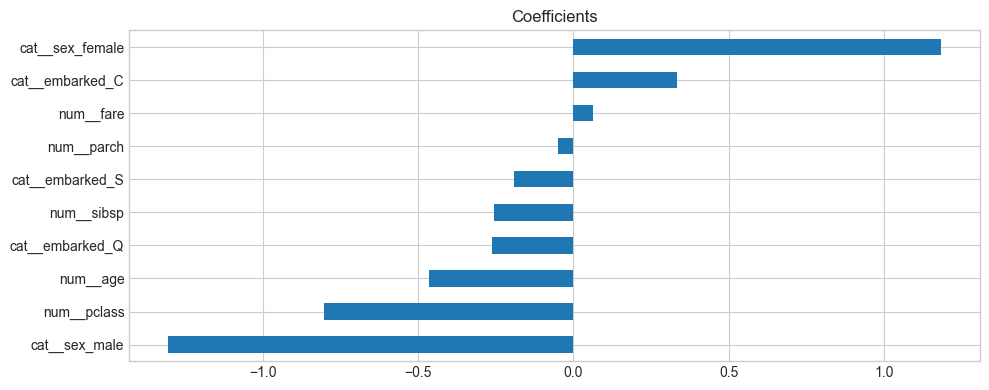

In [10]:
names = model["preprocess"].get_feature_names_out()
pd.Series(model["model"].coef_[0], index=names).sort_values().plot.barh(title="Coefficients");

**Select columns by dtype** instead of listing them. This helps with wide Kaggle tables:

In [11]:
from sklearn.compose import make_column_selector

preprocess_auto = ColumnTransformer([
    ("num", numeric_pipe, make_column_selector(dtype_include="number")),
    ("cat", categorical_pipe, make_column_selector(dtype_include=["object", "category"])),
])
preprocess_auto.fit(X_train.drop(columns="name"), y_train).get_feature_names_out()

array(['num__pclass', 'num__age', 'num__sibsp', 'num__parch', 'num__fare',
       'cat__sex_female', 'cat__sex_male', 'cat__embarked_C',
       'cat__embarked_Q', 'cat__embarked_S'], dtype=object)

## 4. Custom transformers
- **Stateless** (the same function every time) → `FunctionTransformer`.
- **Stateful** (learns something in `fit`) → subclass `BaseEstimator` and `TransformerMixin`. Store what you learn in attributes ending in `_`.

In [12]:
from sklearn.preprocessing import FunctionTransformer

def extract_title(df):
    """'Braund, Mr. Owen Harris' → 'Mr'"""
    return df["name"].str.extract(r",\s*([^\.]+)\.", expand=False).to_frame("title")

def title_name(transformer, input_features):
    return ["title"]

# Use named functions, not lambdas: lambdas can't be pickled, so joblib.dump would fail later
title = FunctionTransformer(extract_title, feature_names_out=title_name)
title.fit_transform(X_train).value_counts().head(8)

title 
Mr        594
Miss      210
Mrs       161
Master     50
Rev         8
Dr          8
Col         4
Ms          2
Name: count, dtype: int64

In [13]:
from sklearn.base import BaseEstimator, TransformerMixin

class RareToOther(BaseEstimator, TransformerMixin):
    """Replace categories rarer than `min_freq` (learned on train) with 'Other'."""

    def __init__(self, min_freq=0.05):
        self.min_freq = min_freq

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.keep_ = {c: X[c].value_counts(normalize=True).loc[lambda s: s >= self.min_freq].index for c in X}
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for c, keep in self.keep_.items():
            X[c] = X[c].where(X[c].isin(keep), "Other")
        return X

    def get_feature_names_out(self, input_features=None):
        return np.array(list(self.keep_))


make_pipeline(title, RareToOther(min_freq=0.02)).fit_transform(X_train).value_counts()

title 
Mr        594
Miss      210
Mrs       161
Master     50
Other      32
Name: count, dtype: int64

Plug the new feature into the `ColumnTransformer` like any other branch:

In [14]:
title_pipe = make_pipeline(title, RareToOther(), OneHotEncoder(handle_unknown="ignore"))

preprocess = ColumnTransformer([
    ("num", numeric_pipe, numeric),
    ("cat", categorical_pipe, categorical),
    ("title", title_pipe, ["name"]),
])
model = Pipeline([("preprocess", preprocess), ("model", LogisticRegression(max_iter=1000))])
model.fit(X_train, y_train)
print(f"test accuracy with title feature: {model.score(X_test, y_test):.3f}")

test accuracy with title feature: 0.824


## 5. Tune the whole pipeline
Parameter names follow the path `step__substep__param`. You can also swap whole steps, for example a scaler for `"passthrough"`.
Any convergence warnings come from the `passthrough` candidates. Logistic regression struggles to converge on unscaled features, which is itself a reason to scale.

In [15]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "preprocess__num__impute__strategy": ["mean", "median"],
    "preprocess__num__scale": [StandardScaler(), "passthrough"],
    "preprocess__title__raretoother__min_freq": [0.01, 0.05],
    "model__C": [0.1, 1, 10],
}
search = GridSearchCV(model, param_grid, cv=5, scoring="accuracy").fit(X_train, y_train)

print("best:", search.best_params_)
print(f"CV accuracy {search.best_score_:.3f} | test accuracy {search.score(X_test, y_test):.3f}")

/opt/homebrew/Caskroom/miniconda/base/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/opt/homebrew/Caskroom/miniconda/base/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.

best: {'model__C': 10, 'preprocess__num__impute__strategy': 'mean', 'preprocess__num__scale': StandardScaler(), 'preprocess__title__raretoother__min_freq': 0.01}
CV accuracy 0.809 | test accuracy 0.824


In [16]:
model.get_params().keys()    # every tunable name in the pipeline

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocess', 'model', 'preprocess__force_int_remainder_cols', 'preprocess__n_jobs', 'preprocess__remainder', 'preprocess__sparse_threshold', 'preprocess__transformer_weights', 'preprocess__transformers', 'preprocess__verbose', 'preprocess__verbose_feature_names_out', 'preprocess__num', 'preprocess__cat', 'preprocess__title', 'preprocess__num__memory', 'preprocess__num__steps', 'preprocess__num__transform_input', 'preprocess__num__verbose', 'preprocess__num__impute', 'preprocess__num__scale', 'preprocess__num__impute__add_indicator', 'preprocess__num__impute__copy', 'preprocess__num__impute__fill_value', 'preprocess__num__impute__keep_empty_features', 'preprocess__num__impute__missing_values', 'preprocess__num__impute__strategy', 'preprocess__num__scale__copy', 'preprocess__num__scale__with_mean', 'preprocess__num__scale__with_std', 'preprocess__cat__memory', 'preprocess__cat__steps', 'preprocess__cat__transform_input', 'prepr

## 6. Why it matters: leakage
Choose 20 "best" features out of 5,000 columns of **pure noise**, then cross-validate.
- **Before the split:** the selector has already seen every fold's labels, so the score looks good on noise.
- **Inside a pipeline:** the selector is refit on each training fold, and the score drops to chance, which is the honest answer.

In [17]:
from sklearn.feature_selection import SelectKBest
from sklearn.model_selection import cross_val_score

rng = np.random.default_rng(0)
X_noise, y_noise = rng.normal(size=(200, 5000)), rng.integers(0, 2, 200)

X_selected = SelectKBest(k=20).fit_transform(X_noise, y_noise)            # ✗ fit on all the data
leaky = cross_val_score(LogisticRegression(), X_selected, y_noise, cv=5).mean()

honest = cross_val_score(make_pipeline(SelectKBest(k=20), LogisticRegression()), X_noise, y_noise, cv=5).mean()
print(f"leaky CV accuracy: {leaky:.2f}   pipeline CV accuracy: {honest:.2f}   (truth: 0.50)")

leaky CV accuracy: 0.79   pipeline CV accuracy: 0.51   (truth: 0.50)


## 7. Save and reload the fitted pipeline
The preprocessing travels with the model, so new raw data can go straight in.

In [18]:
import joblib

joblib.dump(search.best_estimator_, "titanic_pipeline.joblib")
loaded = joblib.load("titanic_pipeline.joblib")
loaded.predict(X_test.head())

array([0, 1, 0, 0, 0])

**Takeaways**
- Put every learned preprocessing step in the pipeline. Anything fitted outside it leaks.
- Use `ColumnTransformer` for per-column preprocessing, `make_column_selector` for wide tables, and `get_feature_names_out` for interpretation.
- Write custom transformers with `FunctionTransformer` (stateless) or `BaseEstimator` + `TransformerMixin` (stateful).
- `GridSearchCV` can tune preprocessing choices along with model hyperparameters.